In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
mu_0 = 4 * np.pi * 1e-7
N = 3000        # число витков
N_dat = 600     # число витков датчика
R = 38 * 1e-3   # радиус катушки 
r = 4.25 * 1e-3 # радиус катушки датчика
L = 0.2         # длинна катушки
freq = 50       # частота тока

##### **Катушка с переменным током**


$$B(x) = \frac{\mu_0 \mu I n}{2} \left( \frac{x + \frac{L}{2}}{\sqrt{R^2 + \left(x + \frac{L}{2}\right)^2}} - \frac{x - \frac{L}{2}}{\sqrt{R^2 + \left(x - \frac{L}{2}\right)^2}} \right)$$

$n = \frac{N}{L}$ — плотность намотки витков, а $x$ — координата вдоль оси соленоида относительно его центра.


In [3]:
def B_theory(dist: np.ndarray) -> np.ndarray:
  n = N / L
  cos1 = (dist + L / 2)/(R**2 + (dist + L/2)**2)**0.5
  cos2 = (dist - L / 2)/(R**2 + (dist - L/2)**2)**0.5
  return mu_0 * mu * I * n / 2  * (cos1 - cos2)

$$B(U) = \frac{U}{2 \pi f N_{\text{дат}} S_{\text{дат}}}$$

где $S_{\text{дат}} = \pi r^2$ — площадь поперечного сечения измерительной катушки (датчика), $f$ (`freq`) — частота переменного тока, $N_{\text{дат}}$ — число витков датчика.


In [4]:
def B_from_U(U: np.ndarray) -> np.ndarray:
  S_dat = np.pi * r**2
  return U / (2 * np.pi * freq * N_dat * S_dat)

In [5]:
U1 = np.array([[131.92, 149.21, 163.01,169.64,176.77,179.50,181.88,182.63,182.78,182.32,180.10,178.95,175.89,170.28,162.72,150.64,133.69,109.71,82.80,64.86,43.95,30.75,21.72,16.88,12.90,9.90,8.00,6.31,5.24,4.56,3.60,3.05,2.57,2.22],
                  [101.78, 112.76, 125.77,131.42,134.96,137.70,139.12,139.57,139.79,139.41,138.45,136.97,134.30,130.50,123.60,114.42,100.40,83.00,59.64,44.36,31.60,22.28,17.13,13.13,10.36,8.04,6.52,5.06,4.21,3.62,3.06,2.51,2.17,1.92],
                  [0.25,0.22,0.21,0.21,0.21,0.21,0.21,0.21,0.21,0.21,0.21,0.21,0.21,0.21,0.21,0.21,0.22,0.67,11.13,61.49,80.75, 59.63,41.52,29.34,21.42,17.25,13.21,10.45,8.14,6.53,5.42,4.79,4.32,3.42]]) * 1e-3

I = 1
mu = 1
dist1 = np.arange(1, U1.shape[1] + 1) * 1e-2

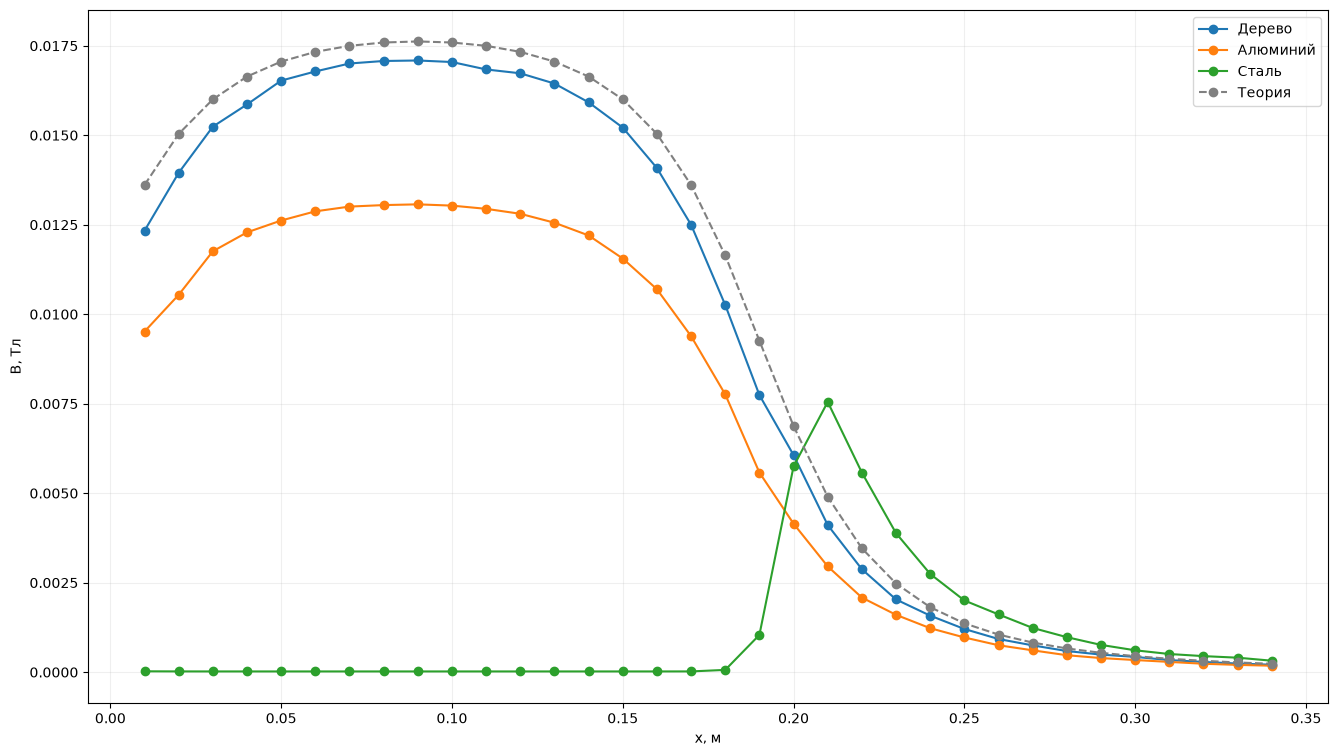

In [6]:
fig, ax, *_ = plt.subplots(1,1,figsize=(16,9))
B_ex =  B_from_U(U1)
ax.plot(dist1,B_ex[0],marker="o", label="Дерево")
ax.plot(dist1,B_ex[1],marker="o", label="Алюминий")
ax.plot(dist1,B_ex[2],marker="o", label="Сталь")

x0 = 0.09
B_th = B_theory(dist1 - x0)
ax.plot(dist1,B_th, c="gray",marker="o", linestyle="--", label="Теория")

ax.set_xlabel("x, м")
ax.set_ylabel("B, Тл")
ax.grid(alpha=0.2)
ax.legend()

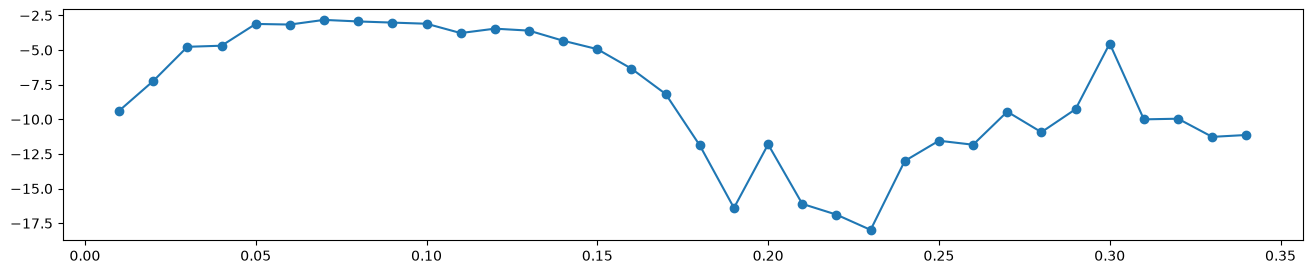

In [7]:
wood_error_percent = -(B_th-B_ex[0]) / B_th * 100
fig_err, ax_err, *_ = plt.subplots(1,1,figsize=(16,3))
ax_err.plot(dist1, wood_error_percent, marker='o')

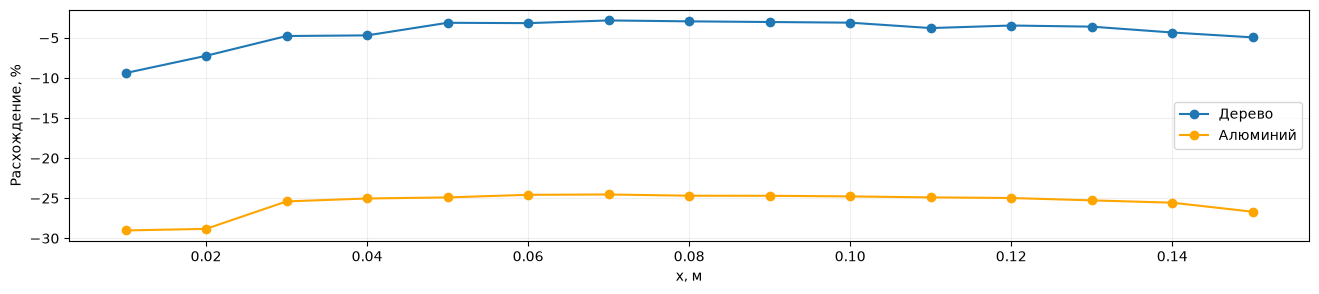

In [8]:
#Дополнительно:
start = 0
end = 0.15
mask = (dist1 >= start) & (dist1 <=end)
# Рассчитываем погрешность для немагнитных материалов (относительно теории при мю=1)
wood_error_percent = -(B_th - B_ex[0]) / B_th * 100
al_error_percent = -(B_th * 0.985 - B_ex[1]) / B_th * 100 / 0.985

# Вычисляем эффективное мю стали по отношению максимумов
mu_steel = np.max(B_ex[2]) / np.max(B_ex[0])

# Теоретическое поле для стали (домножаем теорию вакуума на мю стали)
B_th_steel = B_th * mu_steel
# steel_error_percent = -(B_th_steel - B_ex[2]) / B_th_steel * 100

# Построение графика
fig_err, ax_err, *_ = plt.subplots(1, 1, figsize=(16, 3))

# Наносим кривые с заданными цветами
ax_err.plot(dist1[mask], wood_error_percent[mask], marker='o', label='Дерево')
ax_err.plot(dist1[mask], al_error_percent[mask], marker='o', color='orange', label='Алюминий')
# ax_err.plot(dist1[mask], steel_error_percent[mask], marker='o', color='green', label='Сталь')

# Настройка осей и легенды
ax_err.set_xlabel("x, м")
ax_err.set_ylabel("Расхождение, %")
ax_err.grid(alpha=0.2)
ax_err.legend()

##### **Катушка с постоянным током**

In [9]:
U2 = np.array([[2.673,2.715,2.746,2.771,2.789,2.800,2.806,2.809,2.812,2.813,2.813,2.811,2.808,2.804,2.797,2.787,2.773,2.755,2.725,2.694,2.652,2.621,2.597,2.582,2.571,2.564,2.560,2.557,2.555,2.553,2.552,2.551],
              [2.675,2.716,2.750,2.774,2.788,2.800,2.805,2.808,2.811,2.811,2.810,2.808,2.806,2.802,2.797,2.788,2.774,2.756,2.728,2.692,2.654,2.626,2.600,2.584,2.572,2.566,2.561,2.558,2.555,2.553,2.551,2.549],
              [2.563,2.549,2.548,2.549,2.549,2.549,2.550,2.550,2.550,2.550,2.550,2.549,2.548,2.548,2.548,2.549,2.549,2.549,2.549,2.549,2.566,2.804,3.079,2.990,2.842,2.756,2.694,2.658,2.631,2.614,2.596,2.586]])

dist2 = np.arange(1,U2.shape[1] + 1) * 1e-2

Text(0, 0.5, 'B, Тл')

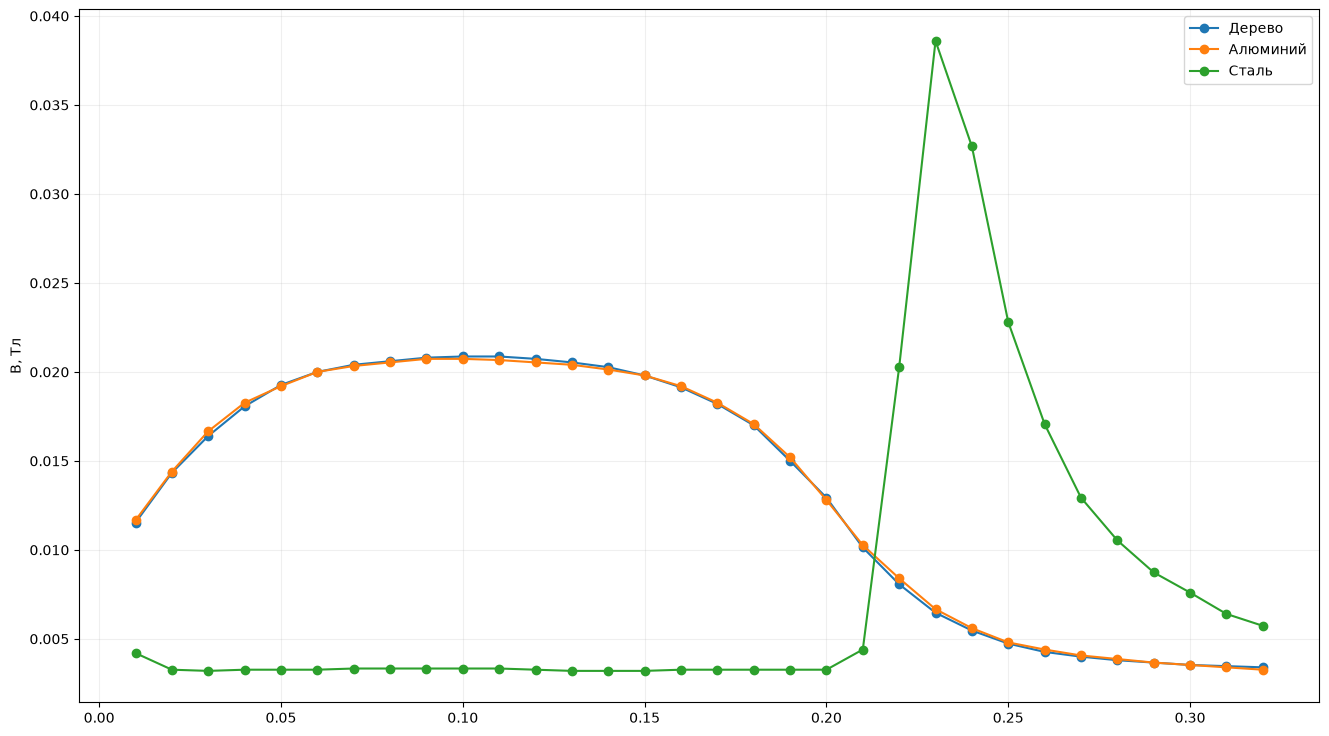

In [10]:
B_hola_ex = (U2 - 2.5) / 15
fig, ax , *_= plt.subplots(1,1,figsize=(16,9))

ax.plot(dist2, B_hola_ex[0], marker='o', label='Дерево')
ax.plot(dist2, B_hola_ex[1], marker='o', label='Алюминий')
ax.plot(dist2, B_hola_ex[2], marker='o', label='Сталь')
I = 1.0
# B_hola_th = B_theory(dist2 - 0.107) 
# ax.plot(dist2, B_hola_th, marker='o', label="Теория")

ax.legend()
ax.grid(alpha=0.2)
ax.set_ylabel("x, м")
ax.set_ylabel("B, Тл")
